In [25]:
import math
import os
import json
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
from matplotlib import rc
from matplotlib.lines import Line2D

rc('font', **{'family': 'sans-serif', 'sans-serif': ['Helvetica']})
mpl.rcParams['savefig.dpi'] = 1200
mpl.rcParams['text.usetex'] = True  # not really needed

import matplotlib.ticker as mticker

with open('momdp_regrets.json', 'r') as f:
    momdp_data = json.load(f)

with open('admdp_regrets.json', 'r') as f:
    admdp_data = json.load(f)

momdp_regrets = {
    'stay': momdp_data['regrets_stay'][:3000],
    'moucbvi': momdp_data['regrets_ucbvi'][:3000],
    'uniform': momdp_data['regrets_uniform'][:3000],
    'routed': momdp_data['regrets_ens'][:3000],
}

admdp_regrets = {
    'stay': admdp_data['regrets_stay'][:3000],
    'moucbvi': admdp_data['regrets_ucbvi'][:3000],
    'routed': admdp_data['regrets_ens'][:3000],
    'uniform': admdp_data['regrets_uniform'][:3000],
}

style_map = {
    'stay': {'color': 'blue', 'linestyle': ':', 'label': r'$\mathrm{Best~stationary~policy}$'},
    
    'moucbvi': {'color': 'green', 'linestyle': '--', 'label': r'$\mathrm{MO}$-$\mathrm{UCBVI}$'},
    'uniform': {'color': 'yellow', 'linestyle': '-.', 'label': r'$\mathrm{Uniform~Ensemble}$'},
    'routed': {'color': 'red', 'linestyle': '-', 'label': r'$\mathrm{Routed~Ensemble}$'},
}

legend_order = ['stay',  'uniform','moucbvi', 'routed']
line_width = 5


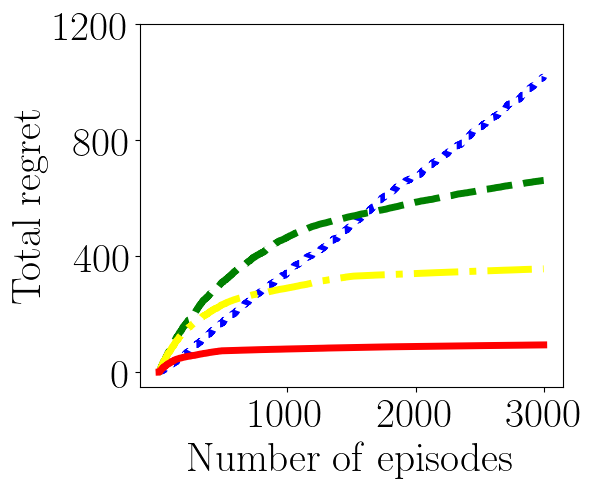

In [27]:
fig_momdp, ax_momdp = plt.subplots(figsize=(6, 5))
ax_momdp.plot(momdp_regrets['stay'], lw=line_width, **style_map['stay'])
ax_momdp.plot(momdp_regrets['moucbvi'], lw=line_width, **style_map['moucbvi'])
ax_momdp.plot(momdp_regrets['uniform'], lw=line_width, **style_map['uniform'])
ax_momdp.plot(momdp_regrets['routed'], lw=line_width, **style_map['routed'])
ax_momdp.set_xlabel(r'$\mathrm{Number~of~episodes}$', fontsize=30)
ax_momdp.set_ylabel(r'$\mathrm{Total~regret}$', fontsize=30)
ax_momdp.set_xticks([1000, 2000, 3000])
ax_momdp.set_yticks([0, 400, 800, 1200])
ax_momdp.tick_params(labelsize=30)
plt.tight_layout()
plt.savefig('momdp_regrets.pdf', dpi=1200, bbox_inches='tight')
plt.show()


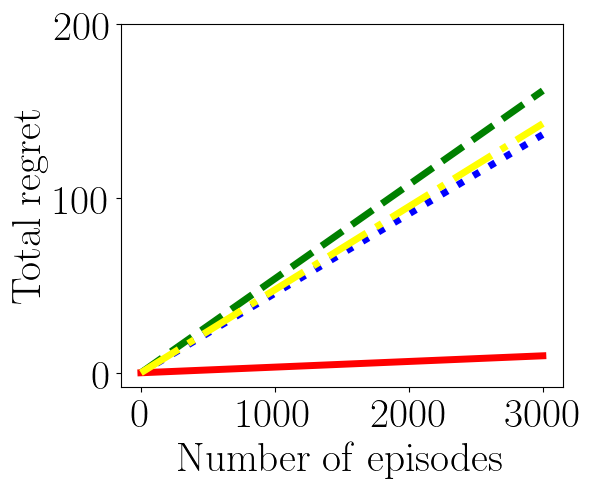

In [28]:
fig_admdp, ax_admdp = plt.subplots(figsize=(6, 5))
ax_admdp.plot(admdp_regrets['stay'], lw=line_width, **style_map['stay'])
ax_admdp.plot(admdp_regrets['moucbvi'], lw=line_width, **style_map['moucbvi'])
ax_admdp.plot(admdp_regrets['routed'], lw=line_width, **style_map['routed'])
ax_admdp.plot(admdp_regrets['uniform'], lw=line_width, **style_map['uniform'])
ax_admdp.set_xlabel(r'$\mathrm{Number~of~episodes}$', fontsize=30)
ax_admdp.set_ylabel(r'$\mathrm{Total~regret}$', fontsize=30)
ax_admdp.set_xticks([0, 1000, 2000, 3000])
ax_admdp.set_yticks([0, 100, 200])
ax_admdp.tick_params(labelsize=30)
plt.tight_layout()
plt.savefig('admdp_regrets.pdf', dpi=1200, bbox_inches='tight')
plt.show()


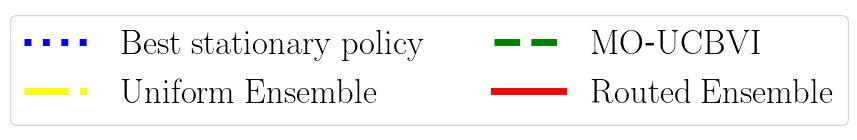

In [29]:
legend_elements = []
legend_labels = []
for key in legend_order:
    style = style_map[key]
    legend_elements.append(Line2D([0], [0], color=style['color'], linestyle=style['linestyle'], lw=line_width))
    legend_labels.append(style['label'])

fig_legend, ax_legend = plt.subplots(figsize=(6, 1.5))
ax_legend.axis('off')
ax_legend.legend(legend_elements, legend_labels, loc='center', ncol=2, fontsize=25)
plt.tight_layout()
plt.savefig('legend.pdf', dpi=1200, bbox_inches='tight')
plt.show()
